In [30]:
# ==========================================
# CELL 1: IMPORT LIBRARIES
# ==========================================

import os
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True


In [31]:

# Cell 1: Imports and environment setup

from pathlib import Path
import os
import random
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
from collections import Counter

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ImageFile.LOAD_TRUNCATED_IMAGES = False

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Imports completed successfully.")


PyTorch version: 2.11.0+cu130
CUDA available: True
Imports completed successfully.


In [32]:

# Cell 2: Locate dataset folders

DATASET_BASE = Path(
    "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset"
)

print("Dataset path exists:", DATASET_BASE.exists())

if DATASET_BASE.exists():
    print("\nTop-level contents:")
    for item in DATASET_BASE.iterdir():
        print(item.name)

# Find train and validation directories
TRAIN_DIR = None
VALID_DIR = None

for root, dirs, files in os.walk(DATASET_BASE):
    folder_names = {d.lower(): d for d in dirs}

    if "train" in folder_names and (
        "valid" in folder_names or "validation" in folder_names
    ):
        TRAIN_DIR = Path(root) / folder_names["train"]

        valid_name = folder_names.get(
            "valid", folder_names.get("validation")
        )
        VALID_DIR = Path(root) / valid_name
        break

if TRAIN_DIR is None or VALID_DIR is None:
    raise FileNotFoundError(
        "Could not locate both train and valid/validation folders. "
        "Check the printed dataset directory structure."
    )

print("\nTraining directory:", TRAIN_DIR)
print("Validation directory:", VALID_DIR)


Dataset path exists: True

Top-level contents:
New Plant Diseases Dataset(Augmented)
new plant diseases dataset(augmented)
test

Training directory: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
Validation directory: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid


In [33]:

# Cell 3: Load dataset structure and count images

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def count_images_by_class(folder):
    class_counts = {}

    for class_folder in sorted(folder.iterdir()):
        if class_folder.is_dir():
            count = sum(
                1 for file in class_folder.rglob("*")
                if file.is_file()
                and file.suffix.lower() in IMAGE_EXTENSIONS
            )
            class_counts[class_folder.name] = count

    return class_counts

train_counts = count_images_by_class(TRAIN_DIR)
valid_counts = count_images_by_class(VALID_DIR)

class_summary = pd.DataFrame({
    "class": sorted(set(train_counts) | set(valid_counts))
})

class_summary["train_images"] = class_summary["class"].map(train_counts).fillna(0).astype(int)
class_summary["validation_images"] = class_summary["class"].map(valid_counts).fillna(0).astype(int)

print("Training classes:", len(train_counts))
print("Validation classes:", len(valid_counts))
print("Total training images:", sum(train_counts.values()))
print("Total validation images:", sum(valid_counts.values()))

display(class_summary.head(10))

print("\nClasses missing from validation:",
      sorted(set(train_counts) - set(valid_counts)))

print("Classes missing from training:",
      sorted(set(valid_counts) - set(train_counts)))


Training classes: 38
Validation classes: 38
Total training images: 70295
Total validation images: 17572


,class,train_images,validation_images
0,Apple___Apple_scab,2016,504
1,Apple___Black_rot,1987,497
2,Apple___Cedar_apple_rust,1760,440
3,Apple___healthy,2008,502
4,Blueberry___healthy,1816,454
5,Cherry_(including_sour)___Powdery_mildew,1683,421
6,Cherry_(including_sour)___healthy,1826,456
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,1642,410
8,Corn_(maize)___Common_rust_,1907,477
9,Corn_(maize)___Northern_Leaf_Blight,1908,477



Classes missing from validation: []
Classes missing from training: []


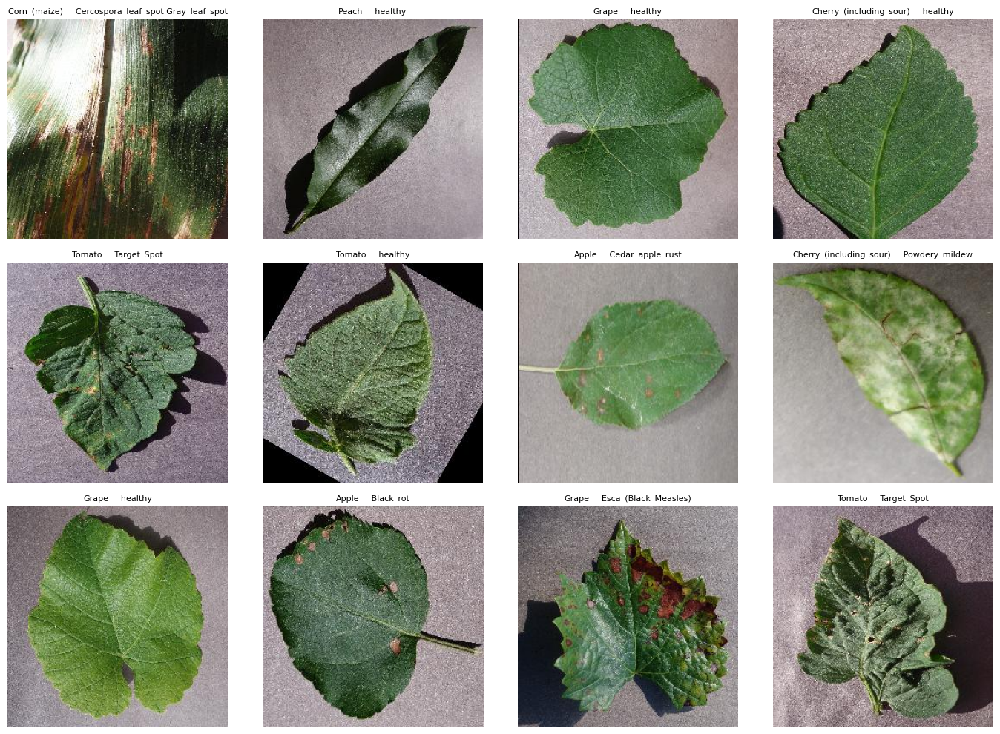

In [34]:

# Cell 4: Display random original training images

class_names = sorted(train_counts.keys())

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for i, ax in enumerate(axes):
    class_name = random.choice(class_names)
    class_path = TRAIN_DIR / class_name

    image_files = [
        f for f in class_path.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if not image_files:
        ax.axis("off")
        continue

    image_path = random.choice(image_files)

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [35]:

# Cell 5: Inspect image dimensions

sample_paths = []

for class_name in class_names:
    class_path = TRAIN_DIR / class_name

    files = [
        f for f in class_path.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    sample_paths.extend(files[:5])

dimension_records = []

for image_path in sample_paths:
    try:
        with Image.open(image_path) as img:
            width, height = img.size
            dimension_records.append({
                "file": image_path.name,
                "class": image_path.parent.name,
                "width": width,
                "height": height,
                "mode": img.mode
            })
    except Exception as error:
        print("Could not inspect:", image_path, error)

dimension_df = pd.DataFrame(dimension_records)

display(dimension_df.head(10))

print("\nDimension summary:")
print(dimension_df[["width", "height"]].describe())

print("\nImage modes:")
print(dimension_df["mode"].value_counts())


,file,class,width,height,mode
0,00075aa8-d81a-4184-8541-b692b78d398a___FREC_Sc...,Apple___Apple_scab,256,256,RGB
1,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,Apple___Apple_scab,256,256,RGB
2,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,Apple___Apple_scab,256,256,RGB
3,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,Apple___Apple_scab,256,256,RGB
4,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,Apple___Apple_scab,256,256,RGB
5,0090d05d-d797-4c99-abd4-3b9cb323a5fd___JR_FrgE...,Apple___Black_rot,256,256,RGB
6,0090d05d-d797-4c99-abd4-3b9cb323a5fd___JR_FrgE...,Apple___Black_rot,256,256,RGB
7,0090d05d-d797-4c99-abd4-3b9cb323a5fd___JR_FrgE...,Apple___Black_rot,256,256,RGB
8,0090d05d-d797-4c99-abd4-3b9cb323a5fd___JR_FrgE...,Apple___Black_rot,256,256,RGB
9,00e909aa-e3ae-4558-9961-336bb0f35db3___JR_FrgE...,Apple___Black_rot,256,256,RGB



Dimension summary:
       width  height
count  190.0   190.0
mean   256.0   256.0
std      0.0     0.0
min    256.0   256.0
25%    256.0   256.0
50%    256.0   256.0
75%    256.0   256.0
max    256.0   256.0

Image modes:
mode
RGB    190
Name: count, dtype: int64


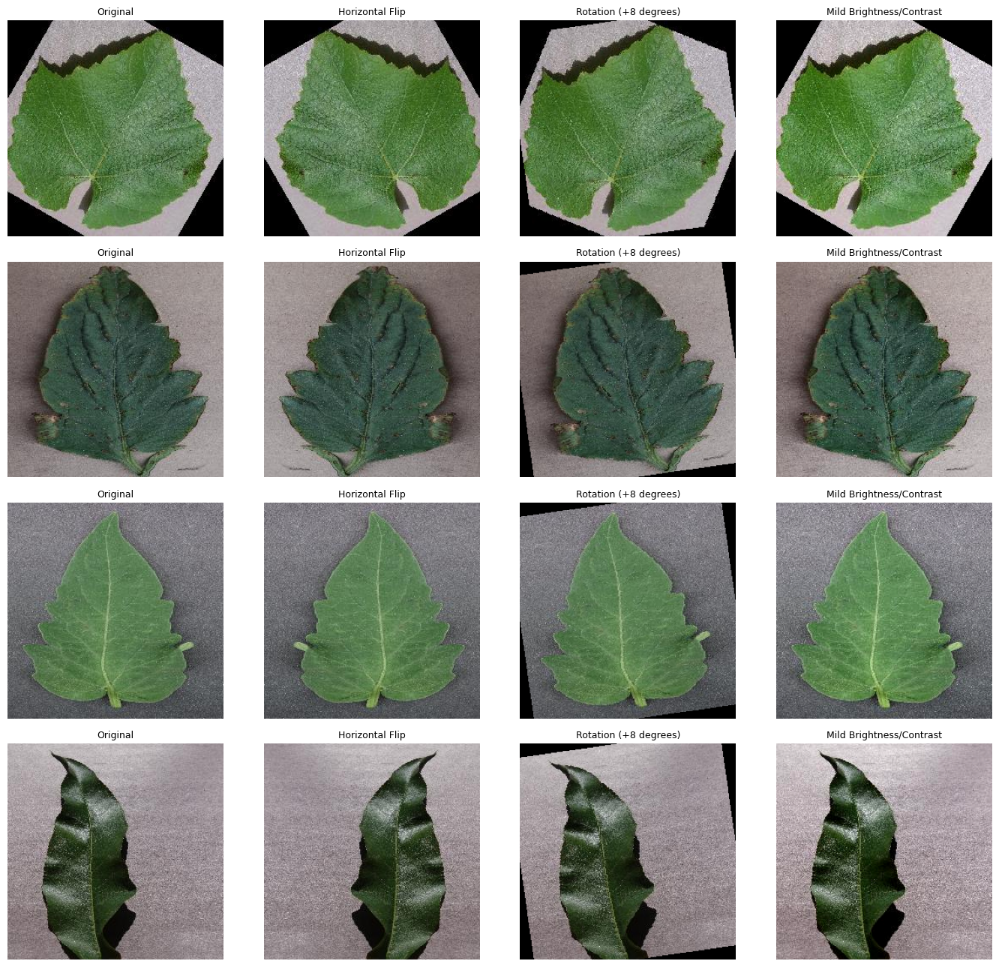

In [36]:

# Cell 6: Compare original and augmented images

import torchvision.transforms.functional as TF

# Select four classes for visual testing
test_classes = random.sample(class_names, 4)

fig, axes = plt.subplots(4, 4, figsize=(14, 13))

for row, class_name in enumerate(test_classes):

    class_path = TRAIN_DIR / class_name

    image_files = [
        f for f in class_path.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    image_path = random.choice(image_files)

    with Image.open(image_path) as img:
        original = img.convert("RGB")

    # 1. Original image
    horizontal_flip = TF.hflip(original)

    # 2. Small rotation
    rotated = TF.rotate(
        original,
        angle=8,
        fill=(0, 0, 0)
    )

    # 3. Mild brightness and contrast adjustment
    adjusted = TF.adjust_brightness(original, brightness_factor=1.1)
    adjusted = TF.adjust_contrast(adjusted, contrast_factor=1.1)

    images = [
        original,
        horizontal_flip,
        rotated,
        adjusted
    ]

    titles = [
        "Original",
        "Horizontal Flip",
        "Rotation (+8 degrees)",
        "Mild Brightness/Contrast"
    ]

    for col, (image, title) in enumerate(zip(images, titles)):
        axes[row, col].imshow(image)
        axes[row, col].set_title(title, fontsize=9)
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        class_name,
        fontsize=8,
        rotation=0,
        labelpad=100
    )

plt.tight_layout()
plt.show()


In [37]:

# Cell 7: Define provisional transformations

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),

    transforms.ToTensor()
])

valid_transform = transforms.Compose([
    transforms.ToTensor()
])

print("Training transformation:")
print(train_transform)

print("\nValidation transformation:")
print(valid_transform)


Training transformation:
Compose(
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    ToTensor()
)

Validation transformation:
Compose(
    ToTensor()
)


In [38]:

# Cell 8: Load transformed datasets

train_dataset = datasets.ImageFolder(
    root=str(TRAIN_DIR),
    transform=train_transform
)

valid_dataset = datasets.ImageFolder(
    root=str(VALID_DIR),
    transform=valid_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))

print("\nTraining classes:", len(train_dataset.classes))
print("Validation classes:", len(valid_dataset.classes))

# Verify that class-to-index mappings are identical
assert train_dataset.class_to_idx == valid_dataset.class_to_idx, \
    "ERROR: Training and validation class mappings do not match!"

print("\nClass mappings match successfully.")

print("\nFirst 10 class mappings:")
print(list(train_dataset.class_to_idx.items())[:10])


Training samples: 70295
Validation samples: 17572

Training classes: 38
Validation classes: 38

Class mappings match successfully.

First 10 class mappings:
[('Apple___Apple_scab', 0), ('Apple___Black_rot', 1), ('Apple___Cedar_apple_rust', 2), ('Apple___healthy', 3), ('Blueberry___healthy', 4), ('Cherry_(including_sour)___Powdery_mildew', 5), ('Cherry_(including_sour)___healthy', 6), ('Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 7), ('Corn_(maize)___Common_rust_', 8), ('Corn_(maize)___Northern_Leaf_Blight', 9)]


In [39]:

# Cell 9: Validate transformed image samples

for i in range(10):

    image_tensor, label = train_dataset[i]

    assert isinstance(image_tensor, torch.Tensor)
    assert image_tensor.shape[0] == 3
    assert image_tensor.shape[1] == 256
    assert image_tensor.shape[2] == 256
    assert torch.isfinite(image_tensor).all()

    assert 0 <= label < len(train_dataset.classes)

print("Training image tensor checks passed.")

for i in range(10):

    image_tensor, label = valid_dataset[i]

    assert image_tensor.shape == (3, 256, 256)
    assert torch.isfinite(image_tensor).all()
    assert 0 <= label < len(valid_dataset.classes)

print("Validation image tensor checks passed.")


Training image tensor checks passed.
Validation image tensor checks passed.


In [40]:

# Cell 10: Check validation determinism

validation_image_1, validation_label_1 = valid_dataset[0]
validation_image_2, validation_label_2 = valid_dataset[0]

assert torch.equal(validation_image_1, validation_image_2)
assert validation_label_1 == validation_label_2

print("Validation determinism check passed.")
print("The same validation image produces identical tensors.")


Validation determinism check passed.
The same validation image produces identical tensors.


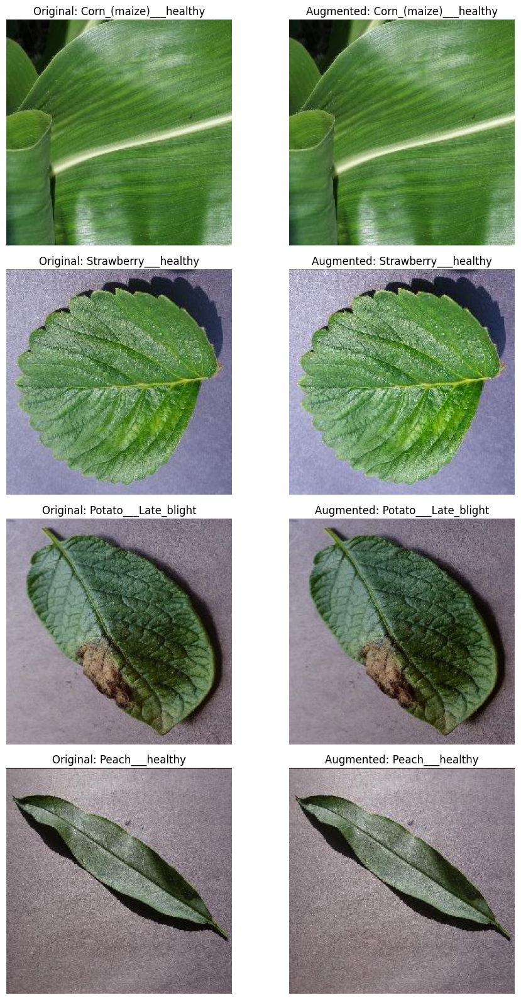

In [41]:

# Cell 11: Original vs augmented image comparison

fig, axes = plt.subplots(4, 2, figsize=(10, 16))

# Select one image from four different classes
selected_classes = random.sample(class_names, 4)

for row, class_name in enumerate(selected_classes):

    class_index = train_dataset.class_to_idx[class_name]

    # Find dataset indexes belonging to this class
    class_indices = [
        i for i, (_, label) in enumerate(train_dataset.samples)
        if label == class_index
    ]

    selected_index = random.choice(class_indices)

    image_path, original_label = train_dataset.samples[selected_index]

    # Load original image
    with Image.open(image_path) as img:
        original_image = img.convert("RGB")

    # Get transformed image
    augmented_tensor, augmented_label = train_dataset[selected_index]

    # Convert tensor to displayable image
    augmented_image = augmented_tensor.permute(1, 2, 0).numpy()

    axes[row, 0].imshow(original_image)
    axes[row, 0].set_title("Original: " + class_name)
    axes[row, 0].axis("off")

    axes[row, 1].imshow(augmented_image)
    axes[row, 1].set_title("Augmented: " + train_dataset.classes[augmented_label])
    axes[row, 1].axis("off")

    assert original_label == augmented_label

plt.tight_layout()
plt.show()


In [42]:

# Cell 12: Create DataLoaders

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))

# Check one training batch
train_images, train_labels = next(iter(train_loader))

print("\nTraining batch:")
print("Image shape:", train_images.shape)
print("Label shape:", train_labels.shape)
print("Image data type:", train_images.dtype)
print("Minimum pixel value:", train_images.min().item())
print("Maximum pixel value:", train_images.max().item())

# Check one validation batch
valid_images, valid_labels = next(iter(valid_loader))

print("\nValidation batch:")
print("Image shape:", valid_images.shape)
print("Label shape:", valid_labels.shape)

# Assertions
assert train_images.shape == (BATCH_SIZE, 3, 256, 256)
assert valid_images.shape == (BATCH_SIZE, 3, 256, 256)

assert train_labels.min() >= 0
assert train_labels.max() < len(class_names)

assert valid_labels.min() >= 0
assert valid_labels.max() < len(class_names)

print("\nDataLoader batch validation passed!")


Training batches: 2197
Validation batches: 550

Training batch:
Image shape: torch.Size([32, 3, 256, 256])
Label shape: torch.Size([32])
Image data type: torch.float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0

Validation batch:
Image shape: torch.Size([32, 3, 256, 256])
Label shape: torch.Size([32])

DataLoader batch validation passed!


In [43]:

# Cell 13: Check repeated augmentation of the same image

sample_index = random.randrange(len(train_dataset))

augmented_versions = [
    train_dataset[sample_index][0]
    for _ in range(4)
]

print("Comparing four transformations of the same image:")

for i in range(3):
    difference = torch.mean(
        torch.abs(augmented_versions[i] - augmented_versions[i + 1])
    )
    print(f"Version {i+1} vs {i+2}: mean difference = {difference.item():.6f}")

print("\nAll versions have the same shape:",
      all(x.shape == augmented_versions[0].shape for x in augmented_versions))


Comparing four transformations of the same image:
Version 1 vs 2: mean difference = 0.009582
Version 2 vs 3: mean difference = 0.109545
Version 3 vs 4: mean difference = 0.052380

All versions have the same shape: True


In [44]:

# Cell 14: Save augmentation configuration

from pathlib import Path
import json
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/member4_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

augmentation_config = {
    "project": "AgriDetect-AI",
    "notebook": "04_augmentation_validation.ipynb",

    "dataset": "New Plant Diseases Dataset (Augmented)",

    "dataset_details": {
        "classes": len(train_dataset.classes),
        "training_images": len(train_dataset),
        "validation_images": len(valid_dataset),
        "image_size": "256x256",
        "image_mode": "RGB"
    },

    "training_augmentation": {
        "horizontal_flip": {
            "enabled": True,
            "probability": 0.5
        },
        "brightness": 0.1,
        "contrast": 0.1,
        "rotation": "Not included in current pipeline"
    },

    "validation_augmentation": {
        "random_augmentation": False,
        "operation": "ToTensor only"
    },

    "normalization": "Pending model confirmation",

    "model_input_size": "Pending model confirmation",

    "status": "PROVISIONAL - pending team confirmation"
}

with open(OUTPUT_DIR / "augmentation_config.json", "w") as file:
    json.dump(augmentation_config, file, indent=4)

print(json.dumps(augmentation_config, indent=4))
print("\nConfiguration saved successfully.")


{
    "project": "AgriDetect-AI",
    "notebook": "04_augmentation_validation.ipynb",
    "dataset": "New Plant Diseases Dataset (Augmented)",
    "dataset_details": {
        "classes": 38,
        "training_images": 70295,
        "validation_images": 17572,
        "image_size": "256x256",
        "image_mode": "RGB"
    },
    "training_augmentation": {
        "horizontal_flip": {
            "enabled": true,
            "probability": 0.5
        },
        "brightness": 0.1,
        "contrast": 0.1,
        "rotation": "Not included in current pipeline"
    },
    "validation_augmentation": {
        "random_augmentation": false,
        "operation": "ToTensor only"
    },
    "normalization": "Pending model confirmation",
    "model_input_size": "Pending model confirmation",
    "status": "PROVISIONAL - pending team confirmation"
}

Configuration saved successfully.


In [45]:

# Cell 15: Generate validation summary

validation_results = {
    "check": [
        "Training dataset loaded",
        "Validation dataset loaded",
        "Training classes verified",
        "Validation classes verified",
        "Class mappings identical",
        "Training tensor validation",
        "Validation tensor validation",
        "Validation determinism",
        "Training DataLoader",
        "Validation DataLoader",
        "Repeated augmentation test"
    ],

    "result": [
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS",
        "PASS"
    ]
}

validation_df = pd.DataFrame(validation_results)

display(validation_df)

validation_df.to_csv(
    OUTPUT_DIR / "augmentation_validation_report.csv",
    index=False
)

print("Validation report saved successfully.")


,check,result
0,Training dataset loaded,PASS
1,Validation dataset loaded,PASS
2,Training classes verified,PASS
3,Validation classes verified,PASS
4,Class mappings identical,PASS
5,Training tensor validation,PASS
6,Validation tensor validation,PASS
7,Validation determinism,PASS
8,Training DataLoader,PASS
9,Validation DataLoader,PASS


Validation report saved successfully.


In [46]:

# Cell 16: Finalization checklist

finalization_status = {
    "Dataset inspection": "Completed",
    "Augmentation visual comparison": "Completed",
    "Provisional training pipeline": "Completed",
    "Validation pipeline": "Completed",
    "Tensor and label checks": "Completed",
    "DataLoader checks": "Completed",
    "Model selection": "Pending Shaurya",
    "Preprocessing configuration": "Pending Avni",
    "Final normalization": "Pending model confirmation",
    "Final augmentation approval": "Pending team review",
    "Cross-split duplicate decision": "Pending team review"
}

for task, status in finalization_status.items():
    print(f"{task}: {status}")


Dataset inspection: Completed
Augmentation visual comparison: Completed
Provisional training pipeline: Completed
Validation pipeline: Completed
Tensor and label checks: Completed
DataLoader checks: Completed
Model selection: Pending Shaurya
Preprocessing configuration: Pending Avni
Final normalization: Pending model confirmation
Final augmentation approval: Pending team review
Cross-split duplicate decision: Pending team review


In [47]:

import os

dataset_path = "/kaggle/input"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        
        if level == 3:
            dirs[:] = []


input/
  datasets/
    vipoooool/
      new-plant-diseases-dataset/


In [48]:

import os

dataset_path = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 5:
        print(
            "  " * level,
            os.path.basename(root),
            "| Files:", len(files),
            "| Subfolders:", len(dirs)
        )


 new-plant-diseases-dataset | Files: 0 | Subfolders: 3
   New Plant Diseases Dataset(Augmented) | Files: 0 | Subfolders: 1
     New Plant Diseases Dataset(Augmented) | Files: 0 | Subfolders: 2
       train | Files: 0 | Subfolders: 38
         Apple___Apple_scab | Files: 2016 | Subfolders: 0
         Apple___Black_rot | Files: 1987 | Subfolders: 0
         Apple___Cedar_apple_rust | Files: 1760 | Subfolders: 0
         Apple___healthy | Files: 2008 | Subfolders: 0
         Blueberry___healthy | Files: 1816 | Subfolders: 0
         Cherry_(including_sour)___Powdery_mildew | Files: 1683 | Subfolders: 0
         Cherry_(including_sour)___healthy | Files: 1826 | Subfolders: 0
         Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | Files: 1642 | Subfolders: 0
         Corn_(maize)___Common_rust_ | Files: 1907 | Subfolders: 0
         Corn_(maize)___Northern_Leaf_Blight | Files: 1908 | Subfolders: 0
         Corn_(maize)___healthy | Files: 1859 | Subfolders: 0
         Grape___Black_rot

In [49]:

import os

root = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset"

for current, dirs, files in os.walk(root):
    if os.path.basename(current) in ["train", "valid", "test"]:
        print("\nFolder:", current)
        print("Number of class folders:", len(dirs))
        print("Number of direct files:", len(files))

        if dirs:
            print("First 5 subfolders:", dirs[:5])

        if files:
            print("First 5 files:", files[:5])



Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
Number of class folders: 38
Number of direct files: 0
First 5 subfolders: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid
Number of class folders: 38
Number of direct files: 0
First 5 subfolders: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train
Number of class folders: 38
Number of direct files: 0
First 5 subfolders: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueb

In [50]:

import os

dataset_path = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset"

for root, dirs, files in os.walk(dataset_path):
    if os.path.basename(root).lower() in ["train", "valid", "test"]:
        print("\nFolder:", root)
        print("Number of subfolders:", len(dirs))
        print("Number of images:", len([
            f for f in files
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]))



Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
Number of subfolders: 38
Number of images: 0

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid
Number of subfolders: 38
Number of images: 0

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train
Number of subfolders: 38
Number of images: 0

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid
Number of subfolders: 38
Number of images: 0

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test
Number of subfolders: 1
Number of images: 0

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test
Number of subfolder

In [51]:

import os

base_path = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset"

for root, dirs, files in os.walk(base_path):
    if os.path.basename(root).lower() in ["train", "valid", "test"]:
        image_count = 0

        for folder, subdirs, filenames in os.walk(root):
            image_count += sum(
                f.lower().endswith(('.jpg', '.jpeg', '.png'))
                for f in filenames
            )

        print("\nFolder:", root)
        print("Classes:", len(dirs))
        print("Total images:", image_count)



Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
Classes: 38
Total images: 70295

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid
Classes: 38
Total images: 17572

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train
Classes: 38
Total images: 70295

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid
Classes: 38
Total images: 17572

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test
Classes: 1
Total images: 33

Folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test
Classes: 0
Total images: 33


Number of classes: 38
Sample classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight']


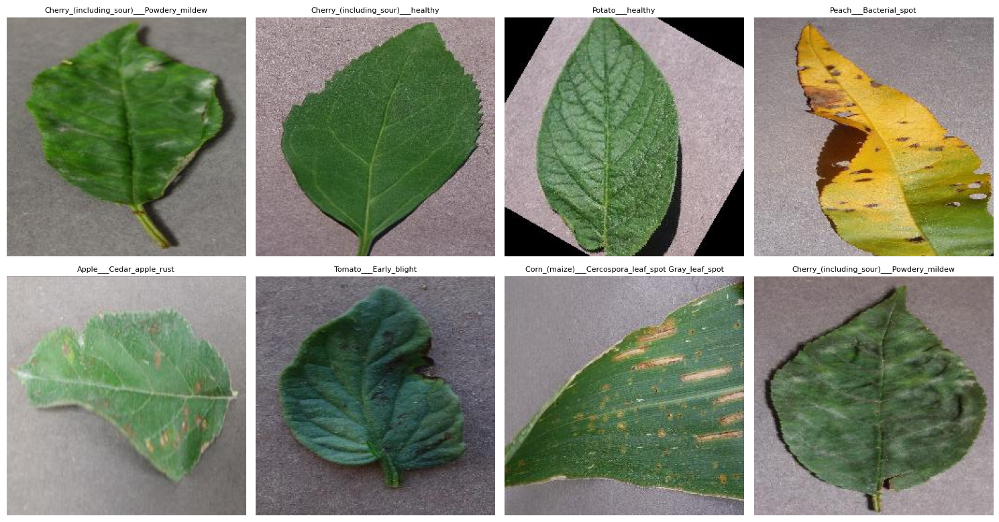

In [52]:

import os
import matplotlib.pyplot as plt
from PIL import Image
import random

# Dataset paths
base_path = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)"

train_dir = os.path.join(base_path, "train")
valid_dir = os.path.join(base_path, "valid")

# Get class names
classes = sorted(os.listdir(train_dir))

print("Number of classes:", len(classes))
print("Sample classes:", classes[:10])

# Display sample images
plt.figure(figsize=(15, 8))

for i in range(8):
    class_name = random.choice(classes)
    class_path = os.path.join(train_dir, class_name)

    images = os.listdir(class_path)
    image_name = random.choice(images)

    image = Image.open(os.path.join(class_path, image_name))

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(class_name, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [53]:

import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


In [54]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

GPU available: True
GPU: Tesla T4


In [55]:

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

valid_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations configured successfully!")


Image transformations configured successfully!


In [58]:

import os
from pathlib import Path
from torchvision import datasets
from torch.utils.data import DataLoader

# Direct dataset paths
DATASET_DIR = Path(
    "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/"
    "new plant diseases dataset(augmented)/"
    "New Plant Diseases Dataset(Augmented)"
)

train_dir = DATASET_DIR / "train"
valid_dir = DATASET_DIR / "valid"

# Check dataset directories
print("Training directory exists:", train_dir.exists())
print("Validation directory exists:", valid_dir.exists())

# Load datasets
if not train_dir.exists() or not valid_dir.exists():
    raise FileNotFoundError("Dataset folders not found. Check dataset path.")

print("Dataset directories located successfully!")



Training directory exists: True
Validation directory exists: True
Dataset directories located successfully!


In [65]:


from torchvision import transforms

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

valid_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])



In [66]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

valid_dataset = datasets.ImageFolder(
    valid_dir,
    transform=valid_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Number of classes:", len(train_dataset.classes))

print("\nPlant disease classes:")
print(train_dataset.classes)


Training images: 70295
Validation images: 17572
Number of classes: 38

Plant disease classes:
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Toma

In [67]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))


Training batches: 2197
Validation batches: 550


In [68]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("GPU available:", torch.cuda.is_available())


Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
GPU available: True


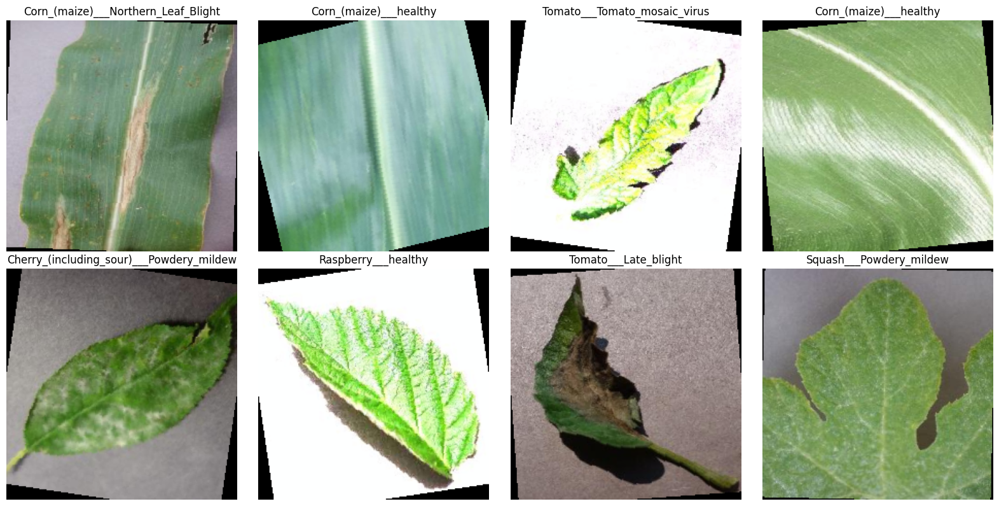

In [69]:

import matplotlib.pyplot as plt
import numpy as np

# Get one batch of training images
images, labels = next(iter(train_loader))

# Display 8 sample images
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, ax in enumerate(axes.flat):
    # Convert tensor to numpy
    img = images[i].permute(1, 2, 0).numpy()

    # Reverse ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img * std + mean
    img = np.clip(img, 0, 1)

    ax.imshow(img)
    ax.set_title(train_dataset.classes[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [70]:

import torch
import torch.nn as nn
from torchvision import models

# Load pre-trained ResNet50
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# Get number of input features
num_features = model.fc.in_features

# Replace final layer for 38 disease classes
model.fc = nn.Linear(num_features, 38)

# Move model to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("ResNet50 model loaded successfully!")
print("Number of output classes:", model.fc.out_features)
print("Device:", device)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 195MB/s] 


ResNet50 model loaded successfully!
Number of output classes: 38
Device: cuda


In [71]:

import torch.optim as optim

# Define loss function
criterion = nn.CrossEntropyLoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Scheduler initialized successfully!")


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Scheduler initialized successfully!


In [72]:

import time

EPOCHS = 3

train_losses = []
valid_losses = []
train_accuracies = []
valid_accuracies = []

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    start_time = time.time()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Validation
    model.eval()
    valid_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            valid_loss += loss.item()
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = valid_loss / len(valid_loader)
    val_acc = 100 * correct / total

    valid_losses.append(val_loss)
    valid_accuracies.append(val_acc)

    scheduler.step()

    elapsed = time.time() - start_time

    print(f"Epoch [{epoch+1}/{EPOCHS}] "
          f"Train Loss: {train_loss:.4f} "
          f"Train Acc: {train_acc:.2f}% "
          f"Val Loss: {val_loss:.4f} "
          f"Val Acc: {val_acc:.2f}% "
          f"Time: {elapsed:.2f}s")


Epoch [1/3] Train Loss: 0.1888 Train Acc: 95.46% Val Loss: 0.0380 Val Acc: 98.74% Time: 3572.15s
Epoch [2/3] Train Loss: 0.0285 Train Acc: 99.20% Val Loss: 0.0173 Val Acc: 99.41% Time: 832.47s
Epoch [3/3] Train Loss: 0.0223 Train Acc: 99.32% Val Loss: 0.0145 Val Acc: 99.50% Time: 831.29s


In [73]:

import torch
import torch.nn as nn
from torchvision import models

# Load pretrained ResNet50
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# Freeze all pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace the final classification layer
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(train_dataset.classes))

# Move model to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Model: ResNet50")
print("Number of classes:", len(train_dataset.classes))
print("Device:", device)
print("ResNet50 loaded successfully!")


Model: ResNet50
Number of classes: 38
Device: cuda
ResNet50 loaded successfully!


In [74]:

import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Train only the classification layer
optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Only the classification layer will be trained.")


Loss function: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.001
Only the classification layer will be trained.


In [75]:

import time

EPOCHS = 3

train_losses = []
train_accuracies = []
valid_losses = []
valid_accuracies = []

start_time = time.time()

for epoch in range(EPOCHS):

    # Training
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # Validation
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_loss / total
    val_acc = 100 * correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    valid_losses.append(val_loss)
    valid_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.2f}%"
    )

total_training_time = time.time() - start_time

print(f"\nStage 1 completed in {total_training_time/60:.2f} minutes.")


Epoch [1/3] Train Loss: 0.5206 Train Acc: 90.76% Val Loss: 0.1806 Val Acc: 96.11%
Epoch [2/3] Train Loss: 0.1553 Train Acc: 96.25% Val Loss: 0.1211 Val Acc: 97.11%
Epoch [3/3] Train Loss: 0.1119 Train Acc: 97.03% Val Loss: 0.0924 Val Acc: 97.52%

Stage 1 completed in 16.19 minutes.


In [76]:

# Unfreeze the deeper ResNet50 layers
for param in model.layer3.parameters():
    param.requires_grad = True

for param in model.layer4.parameters():
    param.requires_grad = True

# Keep the final classification layer trainable
for param in model.fc.parameters():
    param.requires_grad = True

# Configure optimizer for fine-tuning
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

print("Fine-tuning configuration completed!")
print("Trainable layers: layer3, layer4 and fc")
print("Learning rate: 0.0001")


Fine-tuning configuration completed!
Trainable layers: layer3, layer4 and fc
Learning rate: 0.0001


In [77]:

FINE_TUNE_EPOCHS = 3

fine_train_losses = []
fine_train_accuracies = []
fine_valid_losses = []
fine_valid_accuracies = []

fine_tune_start = time.time()

for epoch in range(FINE_TUNE_EPOCHS):

    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_loss / total
    val_acc = 100 * correct / total

    fine_train_losses.append(train_loss)
    fine_train_accuracies.append(train_acc)
    fine_valid_losses.append(val_loss)
    fine_valid_accuracies.append(val_acc)

    print(
        f"Fine-tune Epoch [{epoch+1}/{FINE_TUNE_EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.2f}%"
    )

fine_tuning_time = time.time() - fine_tune_start

print(f"\nFine-tuning completed in {fine_tuning_time/60:.2f} minutes.")


Fine-tune Epoch [1/3] Train Loss: 0.0331 Train Acc: 98.93% Val Loss: 0.0176 Val Acc: 99.43%
Fine-tune Epoch [2/3] Train Loss: 0.0138 Train Acc: 99.53% Val Loss: 0.0116 Val Acc: 99.60%
Fine-tune Epoch [3/3] Train Loss: 0.0109 Train Acc: 99.67% Val Loss: 0.0087 Val Acc: 99.69%

Fine-tuning completed in 27.56 minutes.


In [78]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in valid_loader:
        images = images.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

# Calculate evaluation metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions, average="weighted"
)
recall = recall_score(
    all_labels, all_predictions, average="weighted"
)
f1 = f1_score(
    all_labels, all_predictions, average="weighted"
)

print("FINAL RESNET50 EVALUATION")
print("-------------------------")
print(f"Accuracy:  {accuracy*100:.2f}%")
print(f"Precision: {precision*100:.2f}%")
print(f"Recall:    {recall*100:.2f}%")
print(f"F1-Score:  {f1*100:.2f}%")

print("\nCLASSIFICATION REPORT\n")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=valid_dataset.classes
))


FINAL RESNET50 EVALUATION
-------------------------
Accuracy:  99.69%
Precision: 99.69%
Recall:    99.69%
F1-Score:  99.69%

CLASSIFICATION REPORT

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00       504
                                 Apple___Black_rot       1.00      1.00      1.00       497
                          Apple___Cedar_apple_rust       1.00      1.00      1.00       440
                                   Apple___healthy       1.00      1.00      1.00       502
                               Blueberry___healthy       1.00      1.00      1.00       454
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       421
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.99      0.97      0.98       410
                       

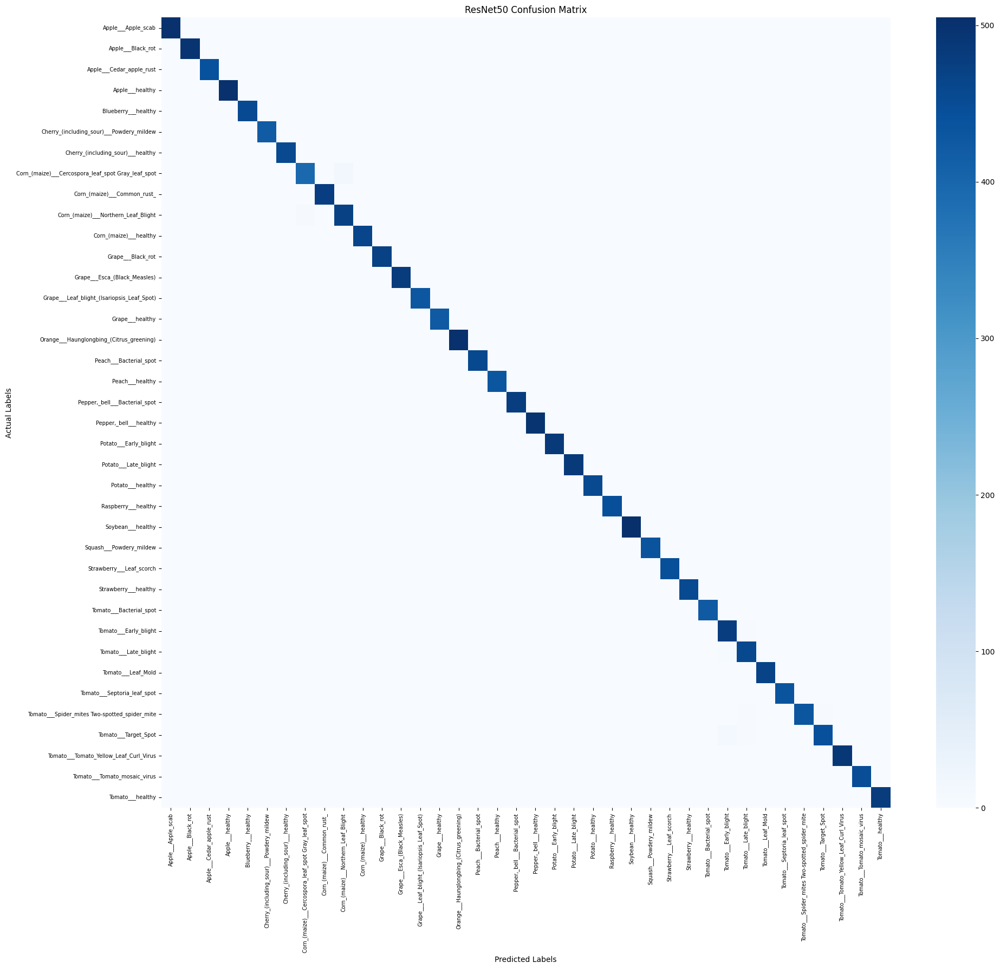

Confusion matrix shape: (38, 38)


In [79]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(20, 18))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=valid_dataset.classes,
    yticklabels=valid_dataset.classes,
    cbar=True
)

plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

plt.show()

print("Confusion matrix shape:", cm.shape)


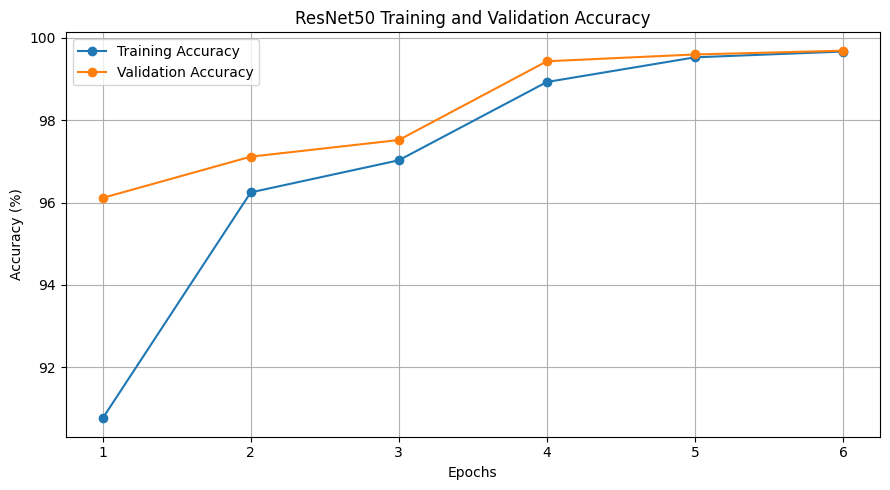

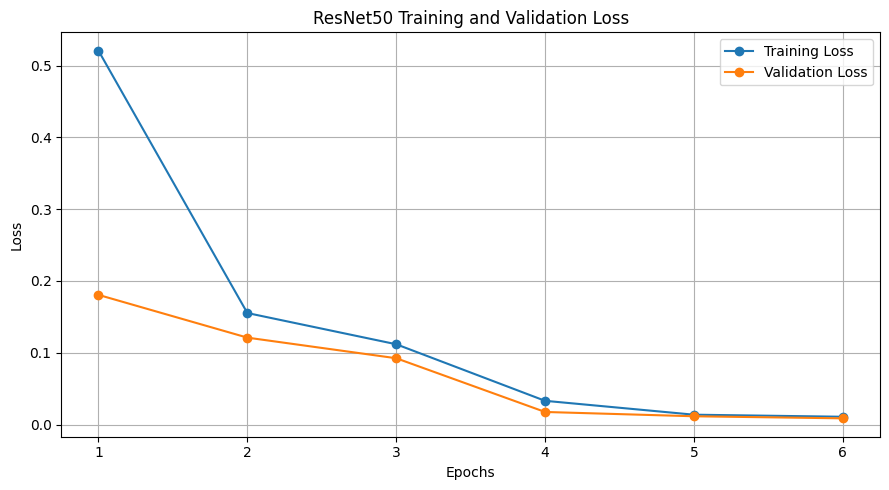

In [80]:

import matplotlib.pyplot as plt

# Combine Stage 1 and Stage 2 history
all_train_acc = train_accuracies + fine_train_accuracies
all_valid_acc = valid_accuracies + fine_valid_accuracies

all_train_loss = train_losses + fine_train_losses
all_valid_loss = valid_losses + fine_valid_losses

epochs = range(1, len(all_train_acc) + 1)

# Accuracy graph
plt.figure(figsize=(9, 5))
plt.plot(epochs, all_train_acc, marker='o', label='Training Accuracy')
plt.plot(epochs, all_valid_acc, marker='o', label='Validation Accuracy')
plt.title("ResNet50 Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Loss graph
plt.figure(figsize=(9, 5))
plt.plot(epochs, all_train_loss, marker='o', label='Training Loss')
plt.plot(epochs, all_valid_loss, marker='o', label='Validation Loss')
plt.title("ResNet50 Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [81]:

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Create results directory
RESULTS_DIR = "results/resnet50"
os.makedirs(RESULTS_DIR, exist_ok=True)

# 1. Save trained ResNet50 model
torch.save(
    model.state_dict(),
    os.path.join(RESULTS_DIR, "resnet50_model.pth")
)

# 2. Save evaluation metrics
metrics = {
    "model": "ResNet50",
    "num_classes": len(valid_dataset.classes),
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "initial_training_time_seconds": float(total_training_time),
    "fine_tuning_time_seconds": float(fine_tuning_time)
}

with open(os.path.join(RESULTS_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=4)

# 3. Save classification report
report = classification_report(
    all_labels,
    all_predictions,
    target_names=valid_dataset.classes
)

with open(os.path.join(RESULTS_DIR, "classification_report.txt"), "w") as f:
    f.write(report)

# 4. Save confusion matrix
pd.DataFrame(
    cm,
    index=valid_dataset.classes,
    columns=valid_dataset.classes
).to_csv(os.path.join(RESULTS_DIR, "confusion_matrix.csv"))

# 5. Save training history
history = {
    "train_accuracy": all_train_acc,
    "validation_accuracy": all_valid_acc,
    "train_loss": all_train_loss,
    "validation_loss": all_valid_loss
}

with open(os.path.join(RESULTS_DIR, "training_history.json"), "w") as f:
    json.dump(history, f, indent=4)

# 6. Save accuracy graph
plt.figure(figsize=(9, 5))
plt.plot(epochs, all_train_acc, marker="o", label="Training Accuracy")
plt.plot(epochs, all_valid_acc, marker="o", label="Validation Accuracy")
plt.title("ResNet50 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "accuracy_graph.png"), dpi=300)
plt.close()

# 7. Save loss graph
plt.figure(figsize=(9, 5))
plt.plot(epochs, all_train_loss, marker="o", label="Training Loss")
plt.plot(epochs, all_valid_loss, marker="o", label="Validation Loss")
plt.title("ResNet50 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "loss_graph.png"), dpi=300)
plt.close()

# 8. Save confusion matrix image
plt.figure(figsize=(20, 18))
plt.imshow(cm, cmap="Blues")
plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.xticks(range(len(valid_dataset.classes)), valid_dataset.classes,
           rotation=90, fontsize=6)
plt.yticks(range(len(valid_dataset.classes)), valid_dataset.classes,
           fontsize=6)
plt.colorbar()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "confusion_matrix.png"), dpi=300)
plt.close()

print("All results saved successfully!")
print("\nSaved files:")
for file in sorted(os.listdir(RESULTS_DIR)):
    print(file)


All results saved successfully!

Saved files:
accuracy_graph.png
classification_report.txt
confusion_matrix.csv
confusion_matrix.png
loss_graph.png
metrics.json
resnet50_model.pth
training_history.json


In [82]:

import os
import time
import json

# 1. Calculate model size
model_path = os.path.join(RESULTS_DIR, "resnet50_model.pth")
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)

# 2. Measure single-image inference latency
model.eval()

images, labels = next(iter(valid_loader))
sample_image = images[0:1].to(device)

# Warm-up runs
with torch.no_grad():
    for _ in range(10):
        _ = model(sample_image)

if device.type == "cuda":
    torch.cuda.synchronize()

# Actual timing
NUM_RUNS = 100
start = time.time()

with torch.no_grad():
    for _ in range(NUM_RUNS):
        _ = model(sample_image)

if device.type == "cuda":
    torch.cuda.synchronize()

end = time.time()

latency_ms = ((end - start) / NUM_RUNS) * 1000

# 3. Save performance details
performance = {
    "model_size_MB": round(model_size_mb, 2),
    "single_image_inference_latency_ms": round(latency_ms, 2),
    "device": str(device),
    "warmup_runs": 10,
    "measured_runs": NUM_RUNS
}

with open(os.path.join(RESULTS_DIR, "performance.json"), "w") as f:
    json.dump(performance, f, indent=4)

print("RESNET50 PERFORMANCE")
print("--------------------")
print(f"Model Size: {model_size_mb:.2f} MB")
print(f"Inference Latency: {latency_ms:.2f} ms per image")
print(f"Device: {device}")
print("\nPerformance details saved successfully!")


RESNET50 PERFORMANCE
--------------------
Model Size: 90.28 MB
Inference Latency: 6.64 ms per image
Device: cuda

Performance details saved successfully!


In [83]:

import os

print("FINAL RESNET50 RESULTS DIRECTORY")
print("=" * 40)

for root, dirs, files in os.walk(RESULTS_DIR):
    for file in sorted(files):
        path = os.path.join(root, file)
        size_kb = os.path.getsize(path) / 1024
        print(f"{file} - {size_kb:.2f} KB")

print("\nTotal files:", len(os.listdir(RESULTS_DIR)))
print("Results folder:", RESULTS_DIR)


FINAL RESNET50 RESULTS DIRECTORY
accuracy_graph.png - 128.71 KB
classification_report.txt - 3.78 KB
confusion_matrix.csv - 4.83 KB
confusion_matrix.png - 686.30 KB
loss_graph.png - 125.55 KB
metrics.json - 0.29 KB
performance.json - 0.14 KB
resnet50_model.pth - 92445.17 KB
training_history.json - 0.78 KB

Total files: 9
Results folder: results/resnet50


       FINAL MODEL PERFORMANCE REPORT
       MODEL ARCHITECTURE: RESNET50
       TASK: PLANT DISEASE CLASSIFICATION

1. MODEL INFORMATION
----------------------------------------
Model Name          : ResNet50
Number of Classes   : 38
Input Image Size    : 224 x 224
Batch Size          : 32
Optimizer           : Adam
Initial Learning Rate: 0.001
Fine-tuning Rate    : 0.0001
Training Epochs     : 6 (3 + 3)
Execution Device    : cuda

2. FINAL EVALUATION METRICS
----------------------------------------
Accuracy            : 99.69%
Precision           : 99.69%
Recall              : 99.69%
F1-Score            : 99.69%

3. TRAINING PERFORMANCE
----------------------------------------
Initial Training Time: 16.19 minutes
Fine-tuning Time     : 27.56 minutes
Total Training Time  : 43.75 minutes

4. MODEL PERFORMANCE DETAILS
----------------------------------------
Model Size           : 90.28 MB
Inference Latency    : 6.64 ms/image

5. CLASSIFICATION REPORT
-----------------------------------

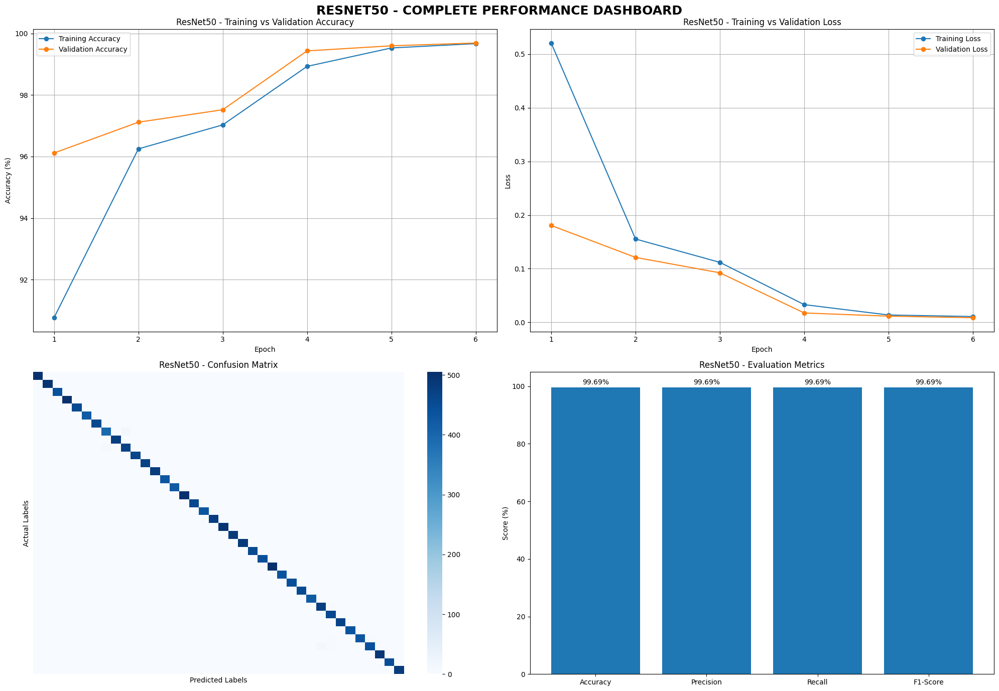


RESNET50 COMPLETE RESULTS DISPLAYED SUCCESSFULLY!
Final report saved as: final_resnet50_report.txt
Results directory: results/resnet50


In [84]:

import os
import json
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# ==========================================
# RESNET50 - COMPLETE MODEL RESULTS
# ==========================================

print("=" * 65)
print("       FINAL MODEL PERFORMANCE REPORT")
print("       MODEL ARCHITECTURE: RESNET50")
print("       TASK: PLANT DISEASE CLASSIFICATION")
print("=" * 65)

print("\n1. MODEL INFORMATION")
print("-" * 40)
print("Model Name          : ResNet50")
print("Number of Classes   :", len(valid_dataset.classes))
print("Input Image Size    : 224 x 224")
print("Batch Size          : 32")
print("Optimizer           : Adam")
print("Initial Learning Rate: 0.001")
print("Fine-tuning Rate    : 0.0001")
print("Training Epochs     : 6 (3 + 3)")
print("Execution Device    :", device)

# ==========================================
# 2. EVALUATION METRICS
# ==========================================

print("\n2. FINAL EVALUATION METRICS")
print("-" * 40)
print(f"Accuracy            : {accuracy*100:.2f}%")
print(f"Precision           : {precision*100:.2f}%")
print(f"Recall              : {recall*100:.2f}%")
print(f"F1-Score            : {f1*100:.2f}%")

# ==========================================
# 3. TRAINING PERFORMANCE
# ==========================================

print("\n3. TRAINING PERFORMANCE")
print("-" * 40)
print(f"Initial Training Time: {total_training_time/60:.2f} minutes")
print(f"Fine-tuning Time     : {fine_tuning_time/60:.2f} minutes")
print(f"Total Training Time  : {(total_training_time+fine_tuning_time)/60:.2f} minutes")

print("\n4. MODEL PERFORMANCE DETAILS")
print("-" * 40)
print(f"Model Size           : {model_size_mb:.2f} MB")
print(f"Inference Latency    : {latency_ms:.2f} ms/image")

# ==========================================
# 5. CLASSIFICATION REPORT
# ==========================================

print("\n5. CLASSIFICATION REPORT")
print("-" * 40)

print(classification_report(
    all_labels,
    all_predictions,
    target_names=valid_dataset.classes,
    digits=4
))

# ==========================================
# 6. TRAINING ACCURACY GRAPH
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(20, 14))

axes[0, 0].plot(epochs, all_train_acc, marker='o',
                label='Training Accuracy')
axes[0, 0].plot(epochs, all_valid_acc, marker='o',
                label='Validation Accuracy')
axes[0, 0].set_title("ResNet50 - Training vs Validation Accuracy")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].set_xticks(list(epochs))
axes[0, 0].legend()
axes[0, 0].grid(True)

# ==========================================
# 7. TRAINING LOSS GRAPH
# ==========================================

axes[0, 1].plot(epochs, all_train_loss, marker='o',
                label='Training Loss')
axes[0, 1].plot(epochs, all_valid_loss, marker='o',
                label='Validation Loss')
axes[0, 1].set_title("ResNet50 - Training vs Validation Loss")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].set_xticks(list(epochs))
axes[0, 1].legend()
axes[0, 1].grid(True)

# ==========================================
# 8. CONFUSION MATRIX
# ==========================================

sns.heatmap(
    cm,
    cmap="Blues",
    ax=axes[1, 0],
    xticklabels=False,
    yticklabels=False
)
axes[1, 0].set_title("ResNet50 - Confusion Matrix")
axes[1, 0].set_xlabel("Predicted Labels")
axes[1, 0].set_ylabel("Actual Labels")

# ==========================================
# 9. METRICS COMPARISON GRAPH
# ==========================================

metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]
metric_values = [
    accuracy * 100,
    precision * 100,
    recall * 100,
    f1 * 100
]

axes[1, 1].bar(metric_names, metric_values)
axes[1, 1].set_title("ResNet50 - Evaluation Metrics")
axes[1, 1].set_ylabel("Score (%)")
axes[1, 1].set_ylim(0, 105)

for i, value in enumerate(metric_values):
    axes[1, 1].text(i, value + 1, f"{value:.2f}%",
                    ha="center")

plt.suptitle(
    "RESNET50 - COMPLETE PERFORMANCE DASHBOARD",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ==========================================
# 10. SAVE FINAL SUMMARY REPORT
# ==========================================

final_report = f"""
FINAL MODEL PERFORMANCE REPORT
================================

Model Architecture: ResNet50
Task: Plant Disease Classification
Number of Classes: {len(valid_dataset.classes)}
Input Size: 224 x 224
Batch Size: 32
Optimizer: Adam

TRAINING CONFIGURATION
Initial Training Epochs: 3
Fine-tuning Epochs: 3
Initial Learning Rate: 0.001
Fine-tuning Learning Rate: 0.0001

EVALUATION METRICS
Accuracy: {accuracy*100:.2f}%
Precision: {precision*100:.2f}%
Recall: {recall*100:.2f}%
F1-Score: {f1*100:.2f}%

TRAINING TIME
Initial Training: {total_training_time/60:.2f} minutes
Fine-tuning: {fine_tuning_time/60:.2f} minutes
Total: {(total_training_time+fine_tuning_time)/60:.2f} minutes

MODEL PERFORMANCE
Model Size: {model_size_mb:.2f} MB
Inference Latency: {latency_ms:.2f} ms/image
Device: {device}

Evaluation Dataset: Validation Dataset
"""

with open(os.path.join(RESULTS_DIR, "final_resnet50_report.txt"), "w") as f:
    f.write(final_report)

print("\n" + "=" * 65)
print("RESNET50 COMPLETE RESULTS DISPLAYED SUCCESSFULLY!")
print("Final report saved as: final_resnet50_report.txt")
print("Results directory:", RESULTS_DIR)
print("=" * 65)
